<a href="https://colab.research.google.com/github/Jerefilms/DEEP-LEARNING/blob/main/Transformers_Samuel_Celis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Arquitectura Transformer
 Samuel David Celis Jeremiche  
**Institución:** Universidad de Cundinamarca — Inteligencia Artificial  


---

In [1]:
# Importación de librerías y configuración reproducible
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, Input
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

np.random.seed(42)
tf.random.set_seed(42)
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


Preparación y Preprocesamiento de la Serie de Tiempo

Generamos una serie temporal sintética no estacionaria con doble componente armónica (estacionalidad diaria y semanal) más ruido gaussiano

In [2]:
# Generación de serie temporal multiescala
pasos = 1200
t = np.arange(pasos)
serie_cruda = (
    0.004 * t +
    1.8 * np.sin(2 * np.pi * t / 24.0) +
    0.9 * np.cos(2 * np.pi * t / 168.0) +
    np.random.normal(0, 0.25, size=pasos)
).reshape(-1, 1)

# Normalización Min-Max estrictamente ajustada sobre el conjunto de entrenamiento
split_idx = int(len(serie_cruda) * 0.8)
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(serie_cruda[:split_idx])
test_scaled = scaler.transform(serie_cruda[split_idx:])

# Creación de ventanas deslizantes
def crear_ventanas(datos, ventana=24):
    X, y = [], []
    for i in range(len(datos) - ventana):
        X.append(datos[i:i + ventana])
        y.append(datos[i + ventana])
    return np.array(X), np.array(y)

VENTANA = 24
X_train, y_train = crear_ventanas(train_scaled, VENTANA)
X_test, y_test = crear_ventanas(test_scaled, VENTANA)

print(f'Dimensiones X_train: {X_train.shape}, y_train: {y_train.shape}')
print(f'Dimensiones X_test:  {X_test.shape}, y_test:  {y_test.shape}')

Dimensiones X_train: (936, 24, 1), y_train: (936, 1)
Dimensiones X_test:  (216, 24, 1), y_test:  (216, 1)


## Mecanismo de Atención
Construimos una capa personalizada de atención temporal que calcula pesos de importancia ALFA sobre cada paso de la ventana histórica.

In [3]:
class TemporalAttentionLayer(layers.Layer):
    def __init__(self, **kwargs):
        super(TemporalAttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(name='att_weight', shape=(input_shape[-1], 1),
                                 initializer='glorot_uniform', trainable=True)
        self.b = self.add_weight(name='att_bias', shape=(input_shape[1], 1),
                                 initializer='zeros', trainable=True)
        super(TemporalAttentionLayer, self).build(input_shape)

    def call(self, inputs):
        # Puntuación de alineación: e = tanh(H * W + b)
        e = tf.keras.backend.tanh(tf.keras.backend.dot(inputs, self.W) + self.b)
        # Distribución de probabilidad Softmax sobre el eje temporal
        alpha = tf.keras.backend.softmax(e, axis=1)
        # Vector de contexto ponderado
        contexto = tf.keras.backend.sum(inputs * alpha, axis=1)
        return contexto, alpha

def construir_modelo_atencion(ventana, n_features=1):
    inp = Input(shape=(ventana, n_features))
    secuencia = layers.LSTM(64, return_sequences=True)(inp)
    contexto, pesos_att = TemporalAttentionLayer()(secuencia)
    salida = layers.Dense(1)(contexto)
    modelo = models.Model(inputs=inp, outputs=salida)
    modelo.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return modelo

modelo_att = construir_modelo_atencion(VENTANA)
hist_att = modelo_att.fit(X_train, y_train, epochs=25, batch_size=32, validation_split=0.15, verbose=0)
print('Entrenamiento Modelo con Atención finalizado. Val MSE:', round(hist_att.history['val_loss'][-1], 5))

Entrenamiento Modelo con Atención finalizado. Val MSE: 0.00913


Arquitectura Transformer Básica para Series de Tiempo
Implementamos **Codificación Posicional Sinusoidal**, **Proyección Densa (Embedding)** y un bloque **Transformer Encoder** con `MultiHeadAttention`, conexiones residuales (`Add`), `LayerNormalization` y red `Feed-Forward`.

In [4]:
class PositionalEncoding(layers.Layer):
    def __init__(self, seq_len, d_model):
        super(PositionalEncoding, self).__init__()
        pos = np.arange(seq_len)[:, np.newaxis]
        i = np.arange(d_model)[np.newaxis, :]
        angle_rates = 1 / np.power(10000, (2 * (i // 2)) / np.float32(d_model))
        angle_rads = pos * angle_rates
        angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
        angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])
        self.pos_encoding = tf.cast(angle_rads[np.newaxis, ...], dtype=tf.float32)

    def call(self, inputs):
        return inputs + self.pos_encoding[:, :tf.shape(inputs)[1], :]

def transformer_encoder_block(inputs, d_model, num_heads, ff_dim, dropout=0.1):
    # Multi-Head Self-Attention + Residual + LayerNorm
    attn_output = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)(inputs, inputs)
    attn_output = layers.Dropout(dropout)(attn_output)
    out1 = layers.LayerNormalization(epsilon=1e-6)(inputs + attn_output)

    # Feed-Forward Network + Residual + LayerNorm
    ffn_output = layers.Dense(ff_dim, activation='relu')(out1)
    ffn_output = layers.Dense(d_model)(ffn_output)
    ffn_output = layers.Dropout(dropout)(ffn_output)
    return layers.LayerNormalization(epsilon=1e-6)(out1 + ffn_output)

def construir_transformer_ts(ventana, n_features=1, d_model=64, num_heads=4, ff_dim=128):
    inp = Input(shape=(ventana, n_features))
    # Embedding continuo hacia dimensión d_model
    x = layers.Dense(d_model)(inp)
    x = PositionalEncoding(ventana, d_model)(x)
    # Dos bloques apilados de Transformer Encoder
    x = transformer_encoder_block(x, d_model, num_heads, ff_dim)
    x = transformer_encoder_block(x, d_model, num_heads, ff_dim)
    # Global Average Pooling y capa de regresión
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(32, activation='relu')(x)
    salida = layers.Dense(1)(x)

    modelo = models.Model(inputs=inp, outputs=salida)
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss='mse', metrics=['mae'])
    return modelo

modelo_transformer = construir_transformer_ts(VENTANA)
hist_trans = modelo_transformer.fit(X_train, y_train, epochs=25, batch_size=32, validation_split=0.15, verbose=0)
print('Entrenamiento Transformer finalizado. Val MSE:', round(hist_trans.history['val_loss'][-1], 5))

Entrenamiento Transformer finalizado. Val MSE: 0.00227


## Parte 4: Evaluación Comparativa y Visualización de Resultados

--- MÉTRICAS EN CONJUNTO DE PRUEBA (TEST) ---
Modelo Atención -> RMSE: 1.3668 | MAE: 1.1627
Transformer     -> RMSE: 0.4149 | MAE: 0.3465


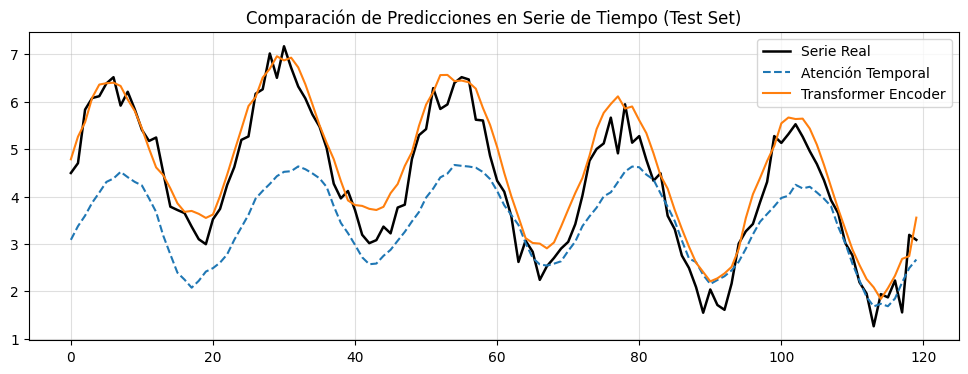

In [5]:
# Predicciones en conjunto de prueba
pred_att = scaler.inverse_transform(modelo_att.predict(X_test, verbose=0))
pred_trans = scaler.inverse_transform(modelo_transformer.predict(X_test, verbose=0))
y_real = scaler.inverse_transform(y_test)

print('--- MÉTRICAS EN CONJUNTO DE PRUEBA (TEST) ---')
print(f'Modelo Atención -> RMSE: {np.sqrt(mean_squared_error(y_real, pred_att)):.4f} | MAE: {mean_absolute_error(y_real, pred_att):.4f}')
print(f'Transformer     -> RMSE: {np.sqrt(mean_squared_error(y_real, pred_trans)):.4f} | MAE: {mean_absolute_error(y_real, pred_trans):.4f}')

plt.figure(figsize=(12, 4))
plt.plot(y_real[:120], label='Serie Real', color='black', linewidth=1.8)
plt.plot(pred_att[:120], label='Atención Temporal', linestyle='--')
plt.plot(pred_trans[:120], label='Transformer Encoder')
plt.title('Comparación de Predicciones en Serie de Tiempo (Test Set)')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()